# Module 2 — Linear Regression: Car Fuel Efficiency

**Course:** ML Zoomcamp 2026.  
**Dataset:** [2026 Car Fuel Efficiency dataset](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv). 
**Homework spec:** [homework.md](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/02-regression/homework.md).  
**Author:** Somasekhar Reddy      **Date:** 18/09/2026


## Goal

Build a linear regression model to predict `fuel_efficiency_mpg` from a subset of the dataset's columns, using this feature set:

- `engine_displacement`
- `horsepower`
- `vehicle_weight`
- `model_year`

Along the way: handle missing values, implement regression from scratch (normal equation, per course convention), evaluate with RMSE, add regularization, and check stability across random seeds.

## Questions

| # | Question |
|---|----------|
| Q1 | There's one column with missing values. What is it? |
| Q2 | What's the median (50th percentile) for `horsepower`? |
| Q3 | Fill missing values with 0 vs. mean — which gives better validation RMSE? |
| Q4 | Try several regularization parameters `r` — which gives the best RMSE? |
| Q5 | Try several random seeds for the train/val/test split — what's the std of validation RMSE? |
| Q6 | Combine train+val, retrain with the best `r`, seed 9 — what's the RMSE on the test set? |

---

# 1. Setup

## 1.1 Imports

In [1]:
# Basic imports
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Display helpers (render nice headings/tables inside a single cell)
from IPython.display import display, Markdown

# Show every column when printing a DataFrame (no "..." truncation)
pd.set_option('display.max_columns', None)

## 1.2 Import Data

In [2]:
# Load the pinned 2026 release of the dataset directly from GitHub
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
df = pd.read_csv(url)

## 1.3 Select the columns
The homework tells us to use **only** these five columns: four features and the target (`fuel_efficiency_mpg`).

In [3]:
# Select the columns we need
# Keep only: `engine_displacement`, `horsepower`, `vehicle_weight`, `model_year`, `fuel_efficiency_mpg`.
cols_to_keep = ["engine_displacement", "horsepower", "vehicle_weight", "model_year", "fuel_efficiency_mpg"]

# .copy() gives us an independent DataFrame, so later edits
# (e.g. filling NAs) never trigger SettingWithCopy warnings
df = df[cols_to_keep].copy()

# 2. EDA

Before modelling, we want to know: how big is the data, what types are the columns, where are the missing values, what does the target look like, and how do the features relate to it?

## 2.1 Structure, missing values, statistics and dtypes

In [4]:
# Check the top 5 rows of the dataframe
# -> quick sanity check that the columns loaded correctly and values look sensible
display(Markdown("### Head"))
display(df.head())

# Dataset size (rows, columns)
display(Markdown("### Shape"))
print(df.shape)

# Check for missing values (count of NaNs per column)
# -> only one column should have NaNs; this is the answer to Question 1
display(Markdown("### Missing Values"))
display(df.isnull().sum())

# Check the data statistics (mean, std, min/max, quartiles)
# -> look at scale differences between columns and at mean vs. median (50%)
#    for a first hint of skewness; the median of `horsepower` answers Question 2
display(Markdown("### Data Statistics"))
display(df.describe())

# Check the data types of the columns
# -> all columns are numeric, so no categorical encoding is needed.
#    `horsepower` is float because NaNs force pandas to use float64
display(Markdown("### Data Types"))
display(df.dtypes)

### Head

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


### Shape

(10000, 5)


### Missing Values

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

### Data Statistics

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


### Data Types

engine_displacement      int64
horsepower             float64
vehicle_weight           int64
model_year               int64
fuel_efficiency_mpg    float64
dtype: object

## 2.2 Target variable: does `fuel_efficiency_mpg` have a long tail?

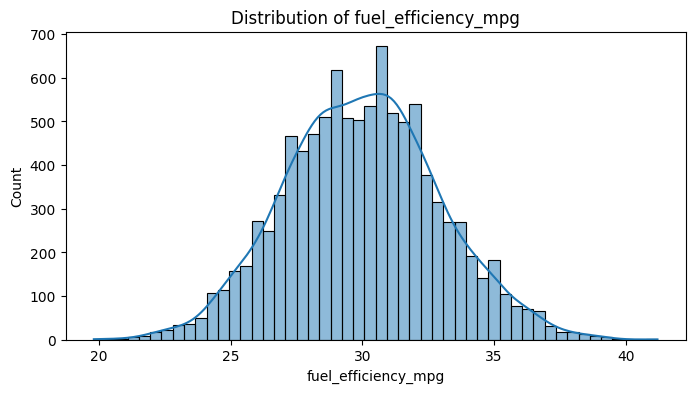

Skewness: 0.081


In [5]:
# Histogram of the target. A long tail would show up as a few very large
# values stretching the right side of the distribution.
plt.figure(figsize=(8, 4))
sns.histplot(df["fuel_efficiency_mpg"], bins=50, kde=True)
plt.title("Distribution of fuel_efficiency_mpg")
plt.xlabel("fuel_efficiency_mpg")
plt.show()

# Skewness: ~0 means symmetric; values well above 1 indicate a long right tail
print("Skewness:", round(df["fuel_efficiency_mpg"].skew(), 3))

**Observation:** the distribution is roughly bell-shaped and symmetric (skewness ≈ 0.08), so there is **no long tail**.
Because of this, we do not need a log-transform of the target for this homework.

## 2.3 Relationships between features

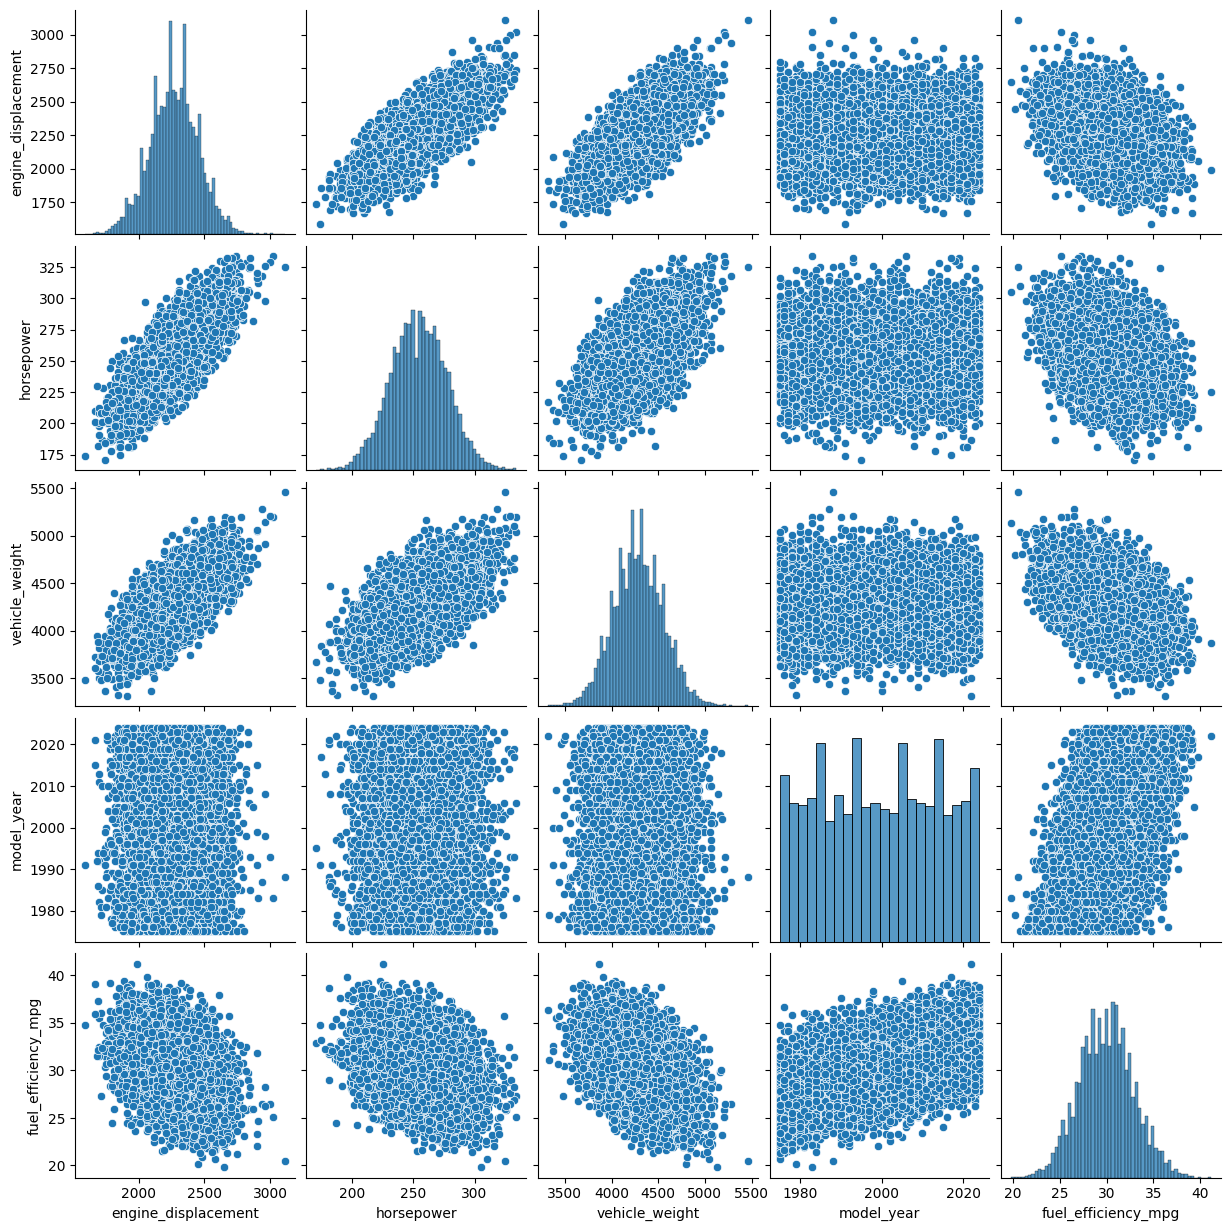

In [6]:
# Visualize all features using a pairplot to see the relationships between them.
# -> diagonal: each variable's distribution; off-diagonal: scatter plots of every pair
sns.pairplot(df)
plt.show()

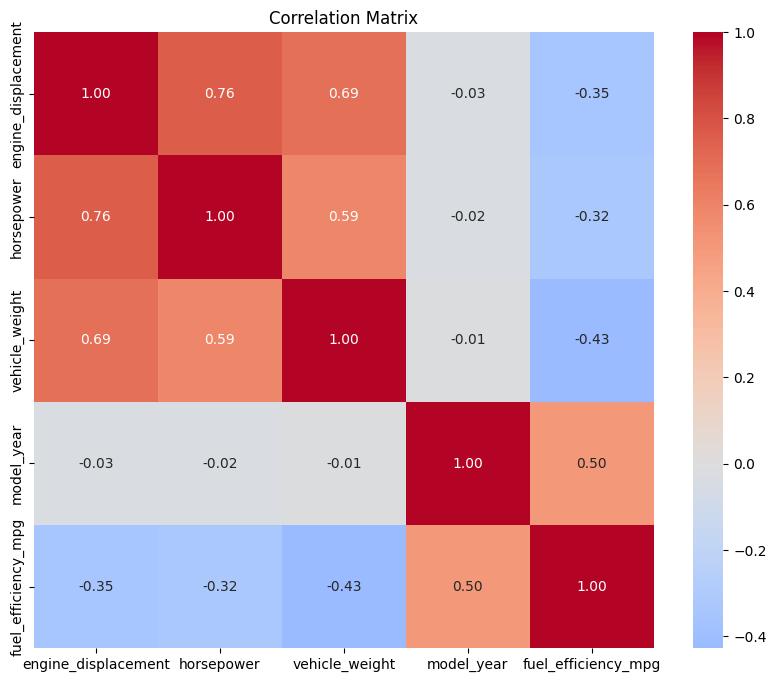

In [7]:
# Visualize the correlation matrix using a heatmap to see how the features are correlated with each other.
# -> values near +1/-1 = strong linear relationship, near 0 = little/no linear relationship
plt.figure(figsize=(10, 8))
plt.title("Correlation Matrix")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Observations**
- `model_year` has the strongest positive correlation with the target (newer cars are more efficient), while `vehicle_weight`, `engine_displacement` and `horsepower` correlate **negatively** (heavier / more powerful cars use more fuel).
- `engine_displacement`, `horsepower` and `vehicle_weight` are strongly correlated with **each other** (multicollinearity). This is why regularization (Q4) can matter: it stabilises the weights when features overlap.

## 2.4 Question 1 — Which column has missing values?

In [8]:
# Keep only columns that actually contain NaNs
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)
print("\nQ1 answer:", list(missing.index))

horsepower    877
dtype: int64

Q1 answer: ['horsepower']


## 2.5 Question 2 — Median of `horsepower`

In [9]:
# .median() skips NaNs by default, so the missing values don't affect it
print("Q2 answer (median horsepower):", df["horsepower"].median())

Q2 answer (median horsepower): 254.0


# 3. Helper functions

All the building blocks are defined once here and reused in Q3–Q6.

- **`split_data`** — shuffles and splits into 60% train / 20% validation / 20% test, exactly as in the lecture. The seed is a parameter because Q5 and Q6 need different seeds.
- **`prepare_X`** — fills `horsepower` NaNs with a given value and returns the feature matrix.
- **`train_linear_regression`** — closed-form **normal equation**: $w = (X^TX)^{-1}X^Ty$.
- **`train_linear_regression_reg`** — same, but with **ridge** regularization: $w = (X^TX + rI)^{-1}X^Ty$. With `r=0` it equals the plain version.
- **`rmse`** — root mean squared error, our evaluation metric.

In [10]:
def split_data(df, seed):
    """Shuffle and split df into 60% train / 20% validation / 20% test."""
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test      # remainder goes to train

    np.random.seed(seed)              # reproducible shuffle
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    return df_train, df_val, df_test


def prepare_X(df, fill_value):
    """Fill NaNs in `horsepower` with fill_value and return the feature matrix."""
    df = df.copy()                    # don't modify the caller's DataFrame
    df["horsepower"] = df["horsepower"].fillna(fill_value)
    features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
    return df[features].values


def train_linear_regression(X, y):
    """Linear regression without regularization (normal equation)."""
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])    # add bias column -> w[0] is the intercept

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]                # (bias, feature weights)


def train_linear_regression_reg(X, y, r=0.0):
    """Ridge regression: adds r to the diagonal of X^T X."""
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])   # regularization term
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]


def predict(X, w0, w):
    """y_hat = w0 + X @ w"""
    return w0 + X.dot(w)


def rmse(y, y_pred):
    """Root mean squared error."""
    return np.sqrt(((y - y_pred) ** 2).mean())

# 4. Question 3 — Imputation: fill with 0 or with the mean?

We split the data with **seed 42**, then compare two ways to handle the NaNs in `horsepower`. 

> ⚠️ The mean must be computed on the **training set only**. Using validation/test data to compute it would leak information from data the model is not supposed to see.

In [11]:
# Split with seed 42 (as in the lecture)
df_train, df_val, df_test = split_data(df, seed=42)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values

print("train / val / test sizes:", len(df_train), len(df_val), len(df_test))

train / val / test sizes: 6000 2000 2000


In [12]:
# Option 1: fill missing horsepower with 0
X_train = prepare_X(df_train, 0)
X_val = prepare_X(df_val, 0)
w0, w = train_linear_regression(X_train, y_train)
rmse_zero = round(rmse(y_val, predict(X_val, w0, w)), 3)

# Option 2: fill missing horsepower with the TRAIN mean
mean_hp = df_train["horsepower"].mean()
X_train = prepare_X(df_train, mean_hp)
X_val = prepare_X(df_val, mean_hp)       # same train mean is applied to validation
w0, w = train_linear_regression(X_train, y_train)
rmse_mean = round(rmse(y_val, predict(X_val, w0, w)), 3)

print(f"RMSE with 0:    {rmse_zero}")
print(f"RMSE with mean: {rmse_mean}")

if rmse_zero < rmse_mean:
    answer = "With 0"
elif rmse_mean < rmse_zero:
    answer = "With mean"
else:
    answer = "Both are equally good"
print("\nQ3 answer:", answer)

RMSE with 0:    2.205
RMSE with mean: 2.202

Q3 answer: With mean


**Takeaway:** filling with the mean gives a slightly lower RMSE. Replacing a missing horsepower with 0 is an unrealistic value (no car has 0 hp) that distorts the fit a little; the mean is a more neutral placeholder.

# 5. Question 4 — Regularization

Now we train a **regularized** linear regression (NaNs filled with **0**) and try several values of `r`. A larger `r` shrinks the weights more strongly.
Scores are rounded to **4 decimals**; on ties we pick the **smallest** `r`.

In [13]:
X_train = prepare_X(df_train, 0)
X_val = prepare_X(df_val, 0)

best_r, best_score = None, float("inf")
results = []

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    score = round(rmse(y_val, predict(X_val, w0, w)), 4)
    results.append((r, score))

    # strict '<' means that on a tie the earlier (smaller) r is kept
    if score < best_score:
        best_r, best_score = r, score

display(pd.DataFrame(results, columns=["r", "val RMSE"]))
print("Q4 answer (best r):", best_r)

,r,val RMSE
0,0.00,2.2053
1,0.01,2.2058
2,0.10,2.2241
3,1.00,2.3492
4,5.00,2.4094
5,10.00,2.4195
6,100.00,2.4292


Q4 answer (best r): 0


**Takeaway:** the RMSE only gets worse as `r` increases, so the best choice is `r = 0` (no regularization). With 6,000 training rows and only 4 features the model isn't overfitting, so extra shrinkage just adds bias.

# 6. Question 5 — How much does the random seed matter?

The split depends on the seed, so the validation score changes with it. We repeat the 60/20/20 split for seeds 0–9 (NaNs filled with 0, **no** regularization) and measure the **standard deviation** of the validation RMSEs. A low std means the model is *stable*.

In [14]:
scores = []

for seed in range(10):
    # New shuffle + split for each seed
    df_train, df_val, df_test = split_data(df, seed)

    X_train = prepare_X(df_train, 0)
    X_val = prepare_X(df_val, 0)
    y_train = df_train["fuel_efficiency_mpg"].values
    y_val = df_val["fuel_efficiency_mpg"].values

    w0, w = train_linear_regression(X_train, y_train)
    scores.append(rmse(y_val, predict(X_val, w0, w)))

# Scores per seed (as plain floats for readable output)
print("Scores per seed:", [round(float(s), 4) for s in scores])
print("\nQ5 answer (std):", round(np.std(scores), 3))

Scores per seed: [2.2392, 2.2021, 2.1634, 2.2044, 2.2019, 2.2458, 2.2697, 2.1908, 2.2166, 2.207]

Q5 answer (std): 0.029


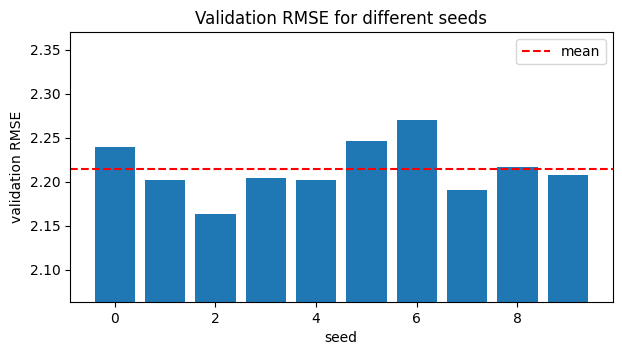

In [15]:
# Optional visual: validation RMSE per seed
plt.figure(figsize=(7, 3.5))
plt.bar(range(10), scores)
plt.axhline(np.mean(scores), color="red", linestyle="--", label="mean")
plt.ylim(min(scores) - 0.1, max(scores) + 0.1)   # zoom in: differences are small
plt.xlabel("seed"); plt.ylabel("validation RMSE")
plt.title("Validation RMSE for different seeds")
plt.legend()
plt.show()

# 7. Question 6 — Final model on the test set

Using **seed 9**: combine the train and validation sets into one bigger training set (more data = better fit), fill NaNs with 0, train with `r = 0.001`, and evaluate **once** on the untouched test set.

In [16]:
df_train, df_val, df_test = split_data(df, seed=9)

# Combine train + validation
df_full_train = pd.concat([df_train, df_val])

X_full = prepare_X(df_full_train, 0)
y_full = df_full_train["fuel_efficiency_mpg"].values

X_test = prepare_X(df_test, 0)
y_test = df_test["fuel_efficiency_mpg"].values

# Train with a tiny regularization r=0.001
w0, w = train_linear_regression_reg(X_full, y_full, r=0.001)

test_rmse = rmse(y_test, predict(X_test, w0, w))
print("Q6 answer (test RMSE):", round(test_rmse, 3))

Q6 answer (test RMSE): 2.236


# 8. Summary of answers

In [17]:
summary = pd.DataFrame({
    "Question": ["EDA: long tail?", "Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "Answer": [
        "No (skew ≈ 0.08)",
        "horsepower",
        int(df["horsepower"].median()),
        answer,
        best_r,
        round(np.std(scores), 3),
        round(test_rmse, 3),
    ],
})
display(summary)

,Question,Answer
0,EDA: long tail?,No (skew ≈ 0.08)
1,Q1,horsepower
2,Q2,254
3,Q3,With mean
4,Q4,0
5,Q5,0.029
6,Q6,2.236
